# NEURAL NETWORKS AND DEEP LEARNING

---
Project: Human Activity Recognition with Wi-Fi (SHARP dataset)

Reference papers:
1. F. Meneghello et al., "SHARP: Environment and Person Independent Activity Recognition With Commodity IEEE 802.11 Access Points," IEEE TMC, 2023.
2. F. Meneghello et al., "A CSI Dataset for Wireless Human Sensing on 80 MHz Wi-Fi Channels," IEEE Comm. Mag., 2023.

This notebook is intentionally kept as simple as possible: plain PyTorch, no extra frameworks, following the same style used in the course labs.


## 1. Setup

`gdown`'s "download a whole folder" mode (`download_folder`) works by scraping Google Drive's web page, and it easily breaks on folders with many files (this one has 500+) even when sharing permissions are correct -- this is a known limitation, not a permissions problem. Downloading a **single file** with `gdown` (`download`, not `download_folder`) is much more reliable, so we download a single zip of `doppler_traces` instead:

1. In Drive, open the shared folder, right-click the `doppler_traces` subfolder and choose **Download**: Drive zips it server-side and downloads a single `doppler_traces.zip` to your computer.
2. Upload that `doppler_traces.zip` file back to Drive (anywhere is fine, e.g. your project folder).
3. Right-click the zip file -> Share -> General access -> "Anyone with the link", then copy the link.
4. Paste that link into `FILE_URL` below.


In [1]:
!pip -q install gdown

import os
import zipfile
import gdown

# TODO: paste here the link to the "doppler_traces.zip" FILE (not a folder link), see instructions above
FILE_URL = "https://drive.google.com/file/d/1qOlNReZNQsv8Agmn6bD47E0w7fqlaOgA/view?usp=sharing"

ZIP_PATH = "/content/doppler_traces.zip"
# where the zip gets extracted to, on the local (fast, temporary) Colab disk
EXTRACT_DIR = "/content/dataset"


In [2]:
# download only if it hasn't been done yet in this runtime (avoids re-downloading on every re-run)
# fuzzy=True lets gdown extract the file id from a normal "view" link, no need to hand-edit the URL
if not os.path.exists(ZIP_PATH):
    gdown.download(url=FILE_URL, output=ZIP_PATH, quiet=False, fuzzy=True)

if not os.path.exists(EXTRACT_DIR):
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)  # unpacks the whole archive into EXTRACT_DIR

print(os.listdir(EXTRACT_DIR))  # sanity check: this should show the S1a, S1b, ... folders (or a "doppler_traces" folder containing them)


Downloading...
From (original): https://drive.google.com/uc?id=1qOlNReZNQsv8Agmn6bD47E0w7fqlaOgA
From (redirected): https://drive.google.com/uc?id=1qOlNReZNQsv8Agmn6bD47E0w7fqlaOgA&confirm=t&uuid=e41ec71a-c2ef-4395-8296-420e2e21b2e1
To: /content/doppler_traces.zip
100%|██████████| 799M/799M [00:20<00:00, 39.0MB/s]


['doppler_traces']


In [3]:
# DATASET_ROOT must point to the folder that directly contains the S1a, S1b, S2a, ... subfolders.
# Depending on how the zip was structured, that's either EXTRACT_DIR itself or EXTRACT_DIR + "/doppler_traces":
DATASET_ROOT = os.path.join(EXTRACT_DIR, "doppler_traces")
if not os.path.isdir(DATASET_ROOT):
    DATASET_ROOT = EXTRACT_DIR  # fallback: the S1a, S1b, ... folders are directly at the root

print("DATASET_ROOT:", DATASET_ROOT)
print(sorted(os.listdir(DATASET_ROOT))[:5], "...")


DATASET_ROOT: /content/dataset/doppler_traces
['.placeholder', 'S1a', 'S1b', 'S1c', 'S2a'] ...


In [4]:
import re
import pickle

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from tqdm import tqdm

seed = 0
torch.manual_seed(seed)   # fixes PyTorch's random initialization/shuffling for reproducibility
np.random.seed(seed)

device = "cuda" if torch.cuda.is_available() else "cpu"  # use the Colab GPU if you enabled one
print("Device:", device)


Device: cuda


## 2. Understanding and loading the dataset

Each file in `doppler_traces/<env>/` is a **Doppler spectrogram trace**: a pickled numpy array of shape `(T, 100)`, where `T` is the number of time samples (it varies a lot from file to file) and `100` is the number of Doppler velocity bins.

The file name encodes three things, e.g. `S4a_J2_stream_1.txt`:
- `S4a`: the environment/measurement set (one of 12 folders: `S1a, S1b, S1c, S2a, S2b, S3a, S4a, S4b, S5a, S6a, S6b, S7a`),
- `J2`: the activity letter (`J`), possibly followed by a repetition number (`2`),
- `stream_1`: which of the 4 receiving antennas the trace comes from.

The activity letters used across the dataset are: `E` (empty room), `J` (jumping), `L` (sitting still), `R` (running), `W` (walking), plus a few extra ones (`C`, `S`, `H`, `LOS`) that only appear in some environments. To keep things simple and comparable across **all** environments, we only use the 5 core activities that are present everywhere: **E, J, L, R, W**. This matches the 5-class setup used in the original SHARP paper (Table 3).

The baseline architecture (see the project slides, "Baseline model") expects, as input, a single-channel image of shape `1 x 340 x 100`: 340 consecutive time samples (about 2 seconds) x 100 Doppler bins. Since each file is much longer than 340 samples, we cut every trace into **non-overlapping windows of length 340**. Each window becomes one training example, labeled with the activity of the file it came from.

**Important for later (multi-antenna decision fusion, section 9):** for a given recording (e.g. `S4a_J2`), the 4 antenna streams (`stream_0` ... `stream_3`) all have exactly the same number of time samples `T` -- they are 4 simultaneous recordings of the very same event. This means that "window number `k`" of `stream_0` and "window number `k`" of `stream_1/2/3` correspond to *the same real time window*, just observed by 4 different antennas. We keep track of this with a `group_id` per window (see `build_dataset` below), so that later we can combine the 4 antennas' predictions for the same real time window.


In [5]:
ACTIVITIES = ["E", "J", "L", "R", "W"]  # the 5 core activities, common to every environment
WIN_LEN = 340   # number of time samples per window (as in the baseline architecture, ~2 seconds)
N_DOPPLER_BINS = 100

# matches e.g. "S4a_J2_stream_1.txt" -> groups: ("S4a", "J2", "1")
# (unlike before, we now keep the full "J2" token, repetition number included, instead of throwing it away)
FNAME_RE = re.compile(r"([A-Za-z0-9]+)_([A-Za-z]+\d*)_stream_(\d)\.txt")


def parse_filename(fname):
    """Extract (environment, activity_letter, antenna_stream, recording_token) from a file name.
    `recording_token` is the activity letter *with* its optional repetition number (e.g. "J2"),
    which uniquely identifies one specific recording within an environment, shared by its 4 antenna streams.
    Returns None if the file does not match the expected naming pattern
    (a handful of files in the dataset have odd names and are simply skipped).
    """
    m = FNAME_RE.match(fname)
    if m is None:
        return None
    env, token, stream = m.group(1), m.group(2), int(m.group(3))
    label = re.match(r"[A-Za-z]+", token).group()  # strip the optional trailing repetition number, e.g. "J2" -> "J"
    return env, label, stream, token


In [6]:
def build_dataset(root_dir, activities=ACTIVITIES, win_len=WIN_LEN):
    """Walk through every environment folder, load every Doppler trace belonging to
    one of `activities`, and cut it into non-overlapping windows of length `win_len`.

    Returns:
        X: float32 array of shape (N, 1, win_len, N_DOPPLER_BINS)
        y: int64 array of shape (N,) with values in [0, len(activities))
        envs: array of shape (N,) with the environment name each window comes from (e.g. "S1a")
        groups: array of shape (N,) with a group id per window, e.g. "S4a_J2_0". Windows with the
                same group id come from the same real time window, recorded simultaneously by the
                (up to) 4 antennas -- used later for multi-antenna decision fusion (section 9).
    """
    X_list, y_list, env_list, group_list = [], [], [], []
    for env in sorted(os.listdir(root_dir)):          # e.g. "S1a", "S1b", ...
        env_dir = os.path.join(root_dir, env)
        if not os.path.isdir(env_dir):
            continue
        for fname in sorted(os.listdir(env_dir)):      # every file inside that environment folder
            parsed = parse_filename(fname)
            if parsed is None:
                continue
            # parsed = parse_filename(fname) is the (env, label, stream, token) tuple returned above;
            # here we need the activity letter and the recording token, "_" throws away the stream index
            # (using "_" as a variable name is just a Python convention for "value I'm not using")
            _, label, _, token = parsed
            if label not in activities:                 # skip activities we're not using (C, S, H, LOS, ...)
                continue
            with open(os.path.join(env_dir, fname), "rb") as f:
                trace = pickle.load(f)  # shape (T, 100), T varies per file

            n_windows = trace.shape[0] // win_len        # how many full, non-overlapping windows fit in this trace
            if n_windows == 0:
                continue
            trace = trace[: n_windows * win_len]         # drop the leftover samples that don't fill a full window
            windows = trace.reshape(n_windows, win_len, -1)  # (n_windows, 340, 100): split the trace into chunks

            X_list.append(windows.astype(np.float32))
            y_list.extend([activities.index(label)] * n_windows)  # same label for every window of this file
            env_list.extend([env] * n_windows)                    # same environment name for every window of this file
            # group id = environment + recording token + window position, WITHOUT the stream index:
            # this is exactly what makes windows from the 4 different antennas "match up" as the same real time window
            group_list.extend([f"{env}_{token}_{i}" for i in range(n_windows)])

    X = np.concatenate(X_list, axis=0)[:, None, :, :]  # add the channel dimension -> (N, 1, 340, 100), as required by Conv2d
    y = np.array(y_list, dtype=np.int64)
    envs = np.array(env_list)
    groups = np.array(group_list)
    return X, y, envs, groups


X, y, envs, groups = build_dataset(DATASET_ROOT)
print("X shape:", X.shape)
print("y shape:", y.shape)
for i, act in enumerate(ACTIVITIES):
    print(f"  {act}: {(y == i).sum()} windows")


X shape: (13564, 1, 340, 100)
y shape: (13564,)
  E: 3012 windows
  J: 2160 windows
  L: 3056 windows
  R: 2684 windows
  W: 2652 windows


### Quick sanity check: plot one window per activity

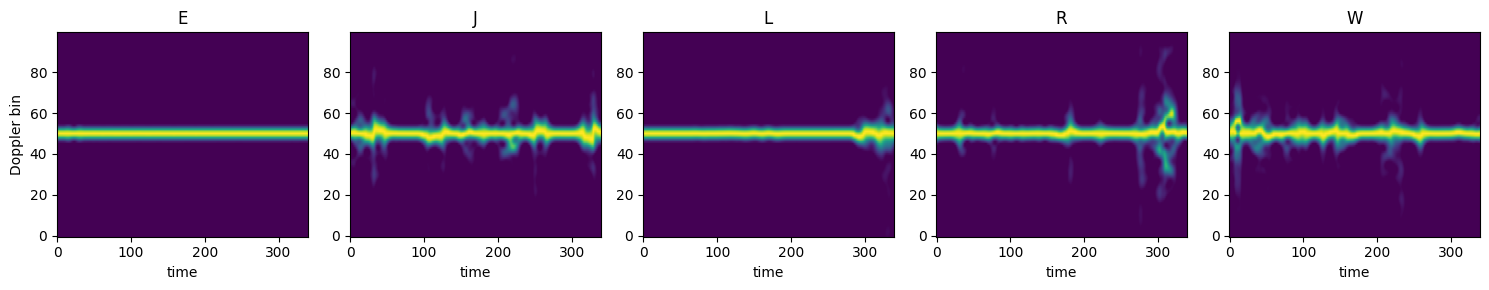

In [7]:
fig, axs = plt.subplots(1, len(ACTIVITIES), figsize=(15, 3))
for i, act in enumerate(ACTIVITIES):
    idx = np.where(y == i)[0][0]              # index of the first window belonging to this activity
    axs[i].imshow(X[idx, 0].T, aspect="auto", origin="lower", cmap="viridis")  # .T: rows=Doppler bins, cols=time, for a readable plot
    axs[i].set_title(act)
    axs[i].set_xlabel("time")
axs[0].set_ylabel("Doppler bin")
plt.tight_layout()
plt.show()


## 3. Dataset class and train/val/test split

Everything already fits comfortably in memory (a few GB), so, exactly like in `AEDataset` from Lab 05, we simply precompute the full tensors once and wrap them in a minimal `Dataset`.

**How to split matters a lot here.** The SHARP paper does **not** split randomly: it trains (and validates) on one environment/person/day (`S1`) and tests on the others, to measure how well the model generalizes to environments, people and days it has never seen. A random split of all windows together would be "easier" and would overestimate real-world performance, because windows from the same file (hence the same person/environment/day) could end up in both train and test.

Below, `TRAIN_ENVS` decides which environment folders are used for training/validation, and everything else is used as the test set. Edit the list to choose whatever combination you want to experiment with (e.g. `["S1a", "S1b", "S1c"]` to reproduce the paper's setup, or add more environments to make the training set larger and the generalization test harder).

**Run all the cells in this notebook in order, top to bottom, at least once (Runtime -> Run all)** before jumping to a later section: variables like `envs_test`, `X_test`, `train_dataloader`, etc. are all defined in this section, and later sections (5, 6, 7, 9, 10) use them. If you re-run only a later cell in a fresh runtime without having executed this one first, you will get a `NameError`.


In [8]:
class DopplerDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)  # keep everything already converted to tensors, no per-item work needed
        self.y = torch.from_numpy(y)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


In [9]:
# environments used for training/validation (like "S1" in the SHARP paper: same environment, same person)
TRAIN_ENVS = ["S1a", "S1b", "S1c"]

ALL_ENVS = sorted(os.listdir(DATASET_ROOT))
TEST_ENVS = [e for e in ALL_ENVS if e not in TRAIN_ENVS]  # every other environment/person/day -> test set
print("Train/val environments:", TRAIN_ENVS)
print("Test environments:", TEST_ENVS)

train_mask = np.isin(envs, TRAIN_ENVS)   # boolean mask: True for every window coming from a TRAIN_ENVS folder
test_mask = np.isin(envs, TEST_ENVS)

X_trainval, y_trainval = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]
envs_test = envs[test_mask]      # environment name of each test window (used to evaluate subsets of the test set separately)
groups_test = groups[test_mask]  # group id of each test window (used for multi-antenna decision fusion, section 9)

# only the train/val windows are split randomly (they all come from the same environments anyway);
# stratify=... keeps the same class proportions in both splits
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.15, stratify=y_trainval, random_state=seed
)

train_dataset = DopplerDataset(X_train, y_train)
val_dataset = DopplerDataset(X_val, y_val)
test_dataset = DopplerDataset(X_test, y_test)

print("Train/Val/Test sizes:", len(train_dataset), len(val_dataset), len(test_dataset))

BATCH_SIZE = 64
train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)   # shuffle=True: reshuffle batches every epoch, only needed for training
val_dataloader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
# shuffle=False here matters beyond convenience: it keeps test_dataloader's sample order identical to
# X_test/y_test/groups_test, which section 9 relies on to match predictions back to their group id
test_dataloader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)


Train/val environments: ['S1a', 'S1b', 'S1c']
Test environments: ['.placeholder', 'S2a', 'S2b', 'S3a', 'S4a', 'S4b', 'S5a', 'S6a', 'S6b', 'S7a']
Train/Val/Test sizes: 2767 489 10308


## 4. Baseline model

We implement the "Baseline model" from the project slides (also described in Fig. 4 of the SHARP paper). It is a small Inception-style block with **3 parallel branches** that all take the `1 x 340 x 100` input and produce feature maps of the same spatial size `170 x 50` (with padding chosen accordingly), so that they can be concatenated along the channel dimension:

- Branch 1: `MaxPool(2x2, stride 2)` -> 1 channel
- Branch 2: `Conv(5 filters, 2x2, stride 2) + ReLU` -> 5 channels
- Branch 3: `Conv(3 filters, 1x1, stride 1) -> Conv(6 filters, 2x2, stride 1, pad 2) -> Conv(9 filters, 4x4, stride 2) + ReLU` -> 9 channels

The 3 branches are concatenated (1 + 5 + 9 = 15 channels), reduced back to 3 channels with a `1x1` convolution, flattened, passed through `Dropout(0.2)` and a final `Dense` layer with one output per activity class.


In [10]:
class BaselineHARNet(nn.Module):
    def __init__(self, num_classes=len(ACTIVITIES)):
        super().__init__()

        # branch 1: just downsamples, no learnable parameters, keeps 1 channel
        self.branch1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # branch 2: a single strided conv, halves both spatial dims (like the pooling branch)
        self.branch2 = nn.Sequential(
            nn.Conv2d(1, 5, kernel_size=2, stride=2),
            nn.ReLU(),
        )

        # branch 3: deeper/finer-grained path. padding=2 on the middle conv is what makes its
        # output spatial size match branch 1 and 2 after the final stride-2 conv (see markdown above)
        self.branch3 = nn.Sequential(
            nn.Conv2d(1, 3, kernel_size=1, stride=1),
            nn.ReLU(),
            nn.Conv2d(3, 6, kernel_size=2, stride=1, padding=2),
            nn.ReLU(),
            nn.Conv2d(6, 9, kernel_size=4, stride=2),
            nn.ReLU(),
        )

        # after concatenation the 3 branches give 1 + 5 + 9 = 15 channels; this 1x1 conv mixes/reduces them to 3
        self.reduce = nn.Sequential(
            nn.Conv2d(1 + 5 + 9, 3, kernel_size=1, stride=1),
            nn.ReLU(),
        )

        self.dropout = nn.Dropout(0.2)  # regularization: randomly zeroes 20% of the flattened features during training
        self.classifier = nn.Linear(3 * 170 * 50, num_classes)  # one output score (logit) per activity class

    def forward(self, x):
        b1 = self.branch1(x)
        b2 = self.branch2(x)
        b3 = self.branch3(x)
        out = torch.cat([b1, b2, b3], dim=1)   # concatenate along the channel dimension (dim=1): requires equal H, W across branches
        out = self.reduce(out)
        out = torch.flatten(out, start_dim=1)  # (batch, channels, H, W) -> (batch, channels*H*W), keeping the batch dim
        out = self.dropout(out)
        out = self.classifier(out)             # returns raw logits, softmax is applied inside CrossEntropyLoss
        return out


model = BaselineHARNet().to(device)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Trainable parameters: {count_parameters(model):,}")
# Expected ~128,535, matching the SHARP paper's baseline model.


Trainable parameters: 128,535


Sanity check: verify the model runs on a dummy batch and the output shape is `(batch_size, num_classes)`.

In [11]:
with torch.no_grad():                                       # no need to track gradients just to check the output shape
    dummy = torch.zeros(4, 1, WIN_LEN, N_DOPPLER_BINS).to(device)  # a fake batch of 4 samples
    out = model(dummy)
    print("Output shape:", out.shape)  # should be (4, 5): 4 samples, 5 class scores each


Output shape: torch.Size([4, 5])


## 5. Training

Standard supervised classification training loop, following the same pattern used in the other labs: cross-entropy loss, Adam optimizer, one pass over train + validation per epoch.

**Early stopping.** Instead of always training for a fixed number of epochs, we stop as soon as the validation loss hasn't improved for `PATIENCE` consecutive epochs. This protects against overfitting (train loss keeps dropping while val loss plateaus or climbs back up) without having to guess the "right" number of epochs in advance. We set `PATIENCE = 5`: a common default, large enough to ride out normal epoch-to-epoch noise in the validation loss, but short enough to not waste time/compute once the model has clearly stopped improving. Since early stopping decides the real stopping point, we also raise the epoch budget (`EPOCHS = 40`) as a safety ceiling that should rarely be reached. We keep the model weights from the best epoch (lowest validation loss), not simply the weights from the last epoch, and restore them before evaluating on the test set.

Note: the training set still pools windows from **all 4 antenna streams together**, exactly as the SHARP paper does ("the Doppler traces collected from the different antennas are used without any distinction among them ... without keeping track of the antenna that generated them"). Multi-antenna information is only used later, at evaluation time (section 9), through decision fusion -- training itself does not change.


In [12]:
criterion = nn.CrossEntropyLoss()  # combines log-softmax + negative log-likelihood, expects raw logits + integer class labels
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)   # The original LR value was set to 1e^-3
EPOCHS = 100      # upper bound on the number of epochs; early stopping will typically stop training well before this
PATIENCE = 5     # stop if the validation loss doesn't improve for this many consecutive epochs


In [13]:
def run_epoch(dataloader, model, criterion, optimizer=None):
    is_train = optimizer is not None      # if no optimizer is passed, we're just evaluating (val/test)
    model.train() if is_train else model.eval()  # toggles dropout on/off

    total_loss, all_preds, all_labels = 0.0, [], []
    with torch.set_grad_enabled(is_train):        # disables autograd during evaluation, saves memory/time
        for batch_x, batch_y in dataloader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)

            logits = model(batch_x)
            loss = criterion(logits, batch_y)

            if is_train:
                optimizer.zero_grad()   # reset gradients accumulated from the previous batch
                loss.backward()         # backpropagation: compute gradients of the loss w.r.t. all parameters
                optimizer.step()        # update the parameters using those gradients

            total_loss += loss.item() * batch_x.size(0)          # un-average the batch loss so we can average over the whole dataset later
            all_preds.append(logits.argmax(dim=1).detach().cpu())  # predicted class = highest-scoring logit
            all_labels.append(batch_y.detach().cpu())

    avg_loss = total_loss / len(dataloader.dataset)
    acc = accuracy_score(torch.cat(all_labels), torch.cat(all_preds))
    return avg_loss, acc


In [14]:
train_losses, val_losses = [], []
train_accs, val_accs = [], []

best_val_loss = float("inf")
epochs_without_improvement = 0
best_state = None   # will hold a copy of the model weights at the best (lowest validation loss) epoch

for epoch in tqdm(range(EPOCHS)):
    tr_loss, tr_acc = run_epoch(train_dataloader, model, criterion, optimizer)   # optimizer passed -> training mode
    va_loss, va_acc = run_epoch(val_dataloader, model, criterion, optimizer=None)  # no optimizer -> evaluation only

    train_losses.append(tr_loss)
    val_losses.append(va_loss)
    train_accs.append(tr_acc)
    val_accs.append(va_acc)

    print(f"Epoch {epoch+1}/{EPOCHS} - train_loss: {tr_loss:.4f}, train_acc: {tr_acc:.4f} "
          f"- val_loss: {va_loss:.4f}, val_acc: {va_acc:.4f}")

    if va_loss < best_val_loss:                     # new best model found
        best_val_loss = va_loss
        epochs_without_improvement = 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}  # snapshot the weights
    else:
        epochs_without_improvement += 1             # no improvement this epoch (covers both "plateaued" and "got worse")

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping triggered: no improvement in validation loss for {PATIENCE} epochs "
              f"(stopped after epoch {epoch+1}).")
        break

if best_state is not None:
    model.load_state_dict(best_state)  # restore the best-epoch weights before evaluating on the test set
    print(f"Restored model weights from the best epoch (val_loss={best_val_loss:.4f}).")


  1%|          | 1/100 [00:01<02:11,  1.33s/it]

Epoch 1/100 - train_loss: 1.6088, train_acc: 0.2273 - val_loss: 1.5846, val_acc: 0.2372


  2%|▏         | 2/100 [00:02<01:45,  1.07s/it]

Epoch 2/100 - train_loss: 1.5639, train_acc: 0.3329 - val_loss: 1.5425, val_acc: 0.3783


  3%|▎         | 3/100 [00:03<01:36,  1.01it/s]

...

Epoch 39/100 - train_loss: 0.9220, train_acc: 0.5801 - val_loss: 1.0028, val_acc: 0.5419


 40%|████      | 40/100 [00:37<00:55,  1.07it/s]

Epoch 40/100 - train_loss: 0.9155, train_acc: 0.5866 - val_loss: 0.9950, val_acc: 0.5297


 40%|████      | 40/100 [00:38<00:57,  1.04it/s]

Epoch 41/100 - train_loss: 0.9215, train_acc: 0.5746 - val_loss: 0.9964, val_acc: 0.5235
Early stopping triggered: no improvement in validation loss for 5 epochs (stopped after epoch 41).
Restored model weights from the best epoch (val_loss=0.9819).


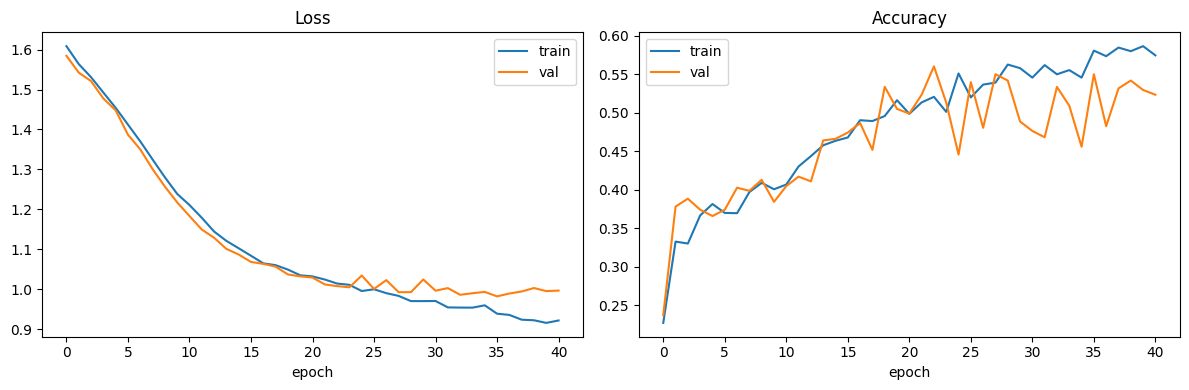

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(train_losses, label="train")
axs[0].plot(val_losses, label="val")
axs[0].set_title("Loss")
axs[0].set_xlabel("epoch")
axs[0].legend()

axs[1].plot(train_accs, label="train")
axs[1].plot(val_accs, label="val")
axs[1].set_title("Accuracy")
axs[1].set_xlabel("epoch")
axs[1].legend()
plt.tight_layout()
plt.show()


## 6. Test set evaluation (all test environments together)

A word of caution on the numbers you'll see here: `TRAIN_ENVS` currently contains a **single** measurement set (`S1`, just one environment/person), while `TEST_ENVS` is **every other** environment/person/day in the dataset. This is the "environment/person-independent" setting the project slides call out as the hard, open challenge -- it is normal to see test accuracy well below what you'd get with a random split (which the model has never done here), and even below 50%, especially with so little training data. This is not necessarily a bug in the code. If you want higher test accuracy, the direct way to get it is to make `TRAIN_ENVS` bigger/more diverse (e.g. add `S2a`, `S3a`, ...) at the cost of having fewer, and less varied, held-out test environments -- exactly the diversity trade-off the slides mention. Section 9 below (multi-antenna decision fusion) also improves on this, without touching `TRAIN_ENVS`.

The confusion matrices below are **row-normalized** (`normalize="true"`): each row (a true activity) sums to 1, so every cell is a fraction in `[0, 1]` -- the fraction of that activity's windows that were predicted as each class. This is often called a "percentage-style" confusion matrix and is easier to compare across environments with different numbers of samples than raw counts would be.


In [16]:
test_loss, test_acc = run_epoch(test_dataloader, model, criterion, optimizer=None)  # optimizer=None -> no weight updates on test data
print(f"Test loss: {test_loss:.4f}, Test accuracy: {test_acc:.4f}")


Test loss: 1.0588, Test accuracy: 0.5125


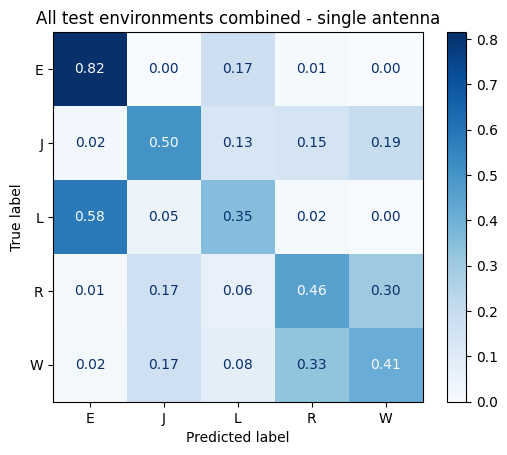

In [17]:
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for batch_x, batch_y in test_dataloader:
        batch_x = batch_x.to(device)
        logits = model(batch_x)
        all_preds.append(logits.argmax(dim=1).cpu())  # take the most likely class per sample
        all_labels.append(batch_y)

all_preds = torch.cat(all_preds).numpy()
all_labels = torch.cat(all_labels).numpy()

# normalize="true": each row (true class) sums to 1, so every cell is in [0, 1] instead of a raw count
cm = confusion_matrix(all_labels, all_preds, labels=list(range(len(ACTIVITIES))), normalize="true")
disp = ConfusionMatrixDisplay(cm, display_labels=ACTIVITIES)
disp.plot(cmap="Blues", values_format=".2f")   # show 2 decimals (e.g. 0.85) instead of raw counts
plt.title("All test environments combined - single antenna")
plt.show()


## 7. Test set evaluation (grouped by measurement set)

The confusion matrix above lumps together every unseen environment in `TEST_ENVS`. Folders that share the same leading number (e.g. `S4a` and `S4b`) come from the same measurement set `S4` (same environment/person, just recorded on different days or sub-runs -- see the dataset paper), so it makes sense to evaluate them **together** rather than one-by-one: one confusion matrix and accuracy per measurement set (`S2`, `S3`, `S4`, `S5`, `S6`, `S7`), using the same trained model (no retraining). As above, matrices are row-normalized to `[0, 1]`.


In [18]:
def env_group(env_name):
    """Map an environment folder name to its measurement-set group, e.g. "S4a" -> "S4", "S4b" -> "S4"."""
    m = re.match(r"(S\d+)", env_name)
    return m.group(1) if m else env_name


# group the test environments by measurement set (e.g. "S4": ["S4a", "S4b"])
test_groups = {}
for env_name in TEST_ENVS:
    group = env_group(env_name)
    test_groups.setdefault(group, []).append(env_name)

print(test_groups)


{'.placeholder': ['.placeholder'], 'S2': ['S2a', 'S2b'], 'S3': ['S3a'], 'S4': ['S4a', 'S4b'], 'S5': ['S5a'], 'S6': ['S6a', 'S6b'], 'S7': ['S7a']}


.placeholder: no windows found, skipping
S2 (S2a, S2b): n=2816, loss=1.0224, acc=0.5089


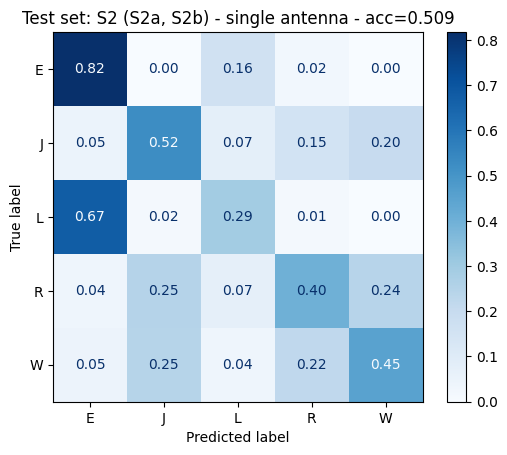

S3 (S3a): n=1104, loss=1.0024, acc=0.5589


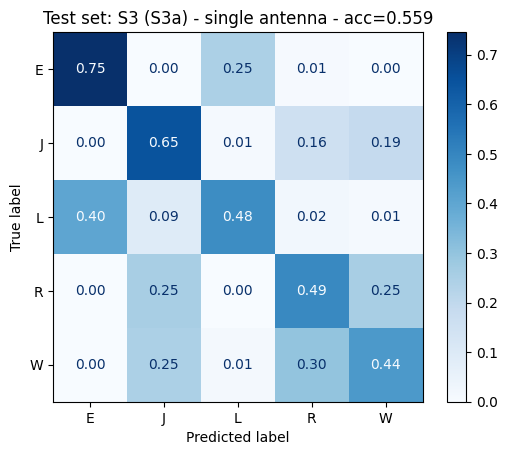

S4 (S4a, S4b): n=2176, loss=1.0195, acc=0.5064


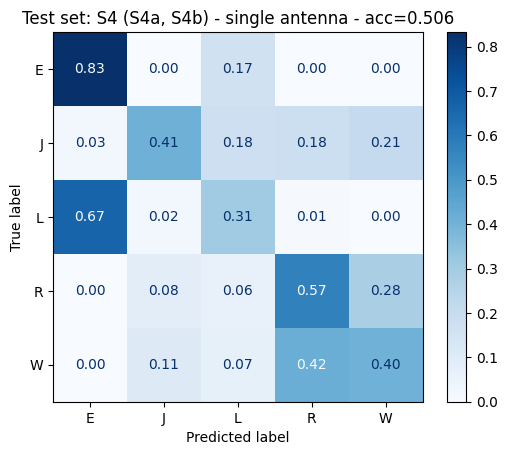

S5 (S5a): n=1092, loss=1.0943, acc=0.4982


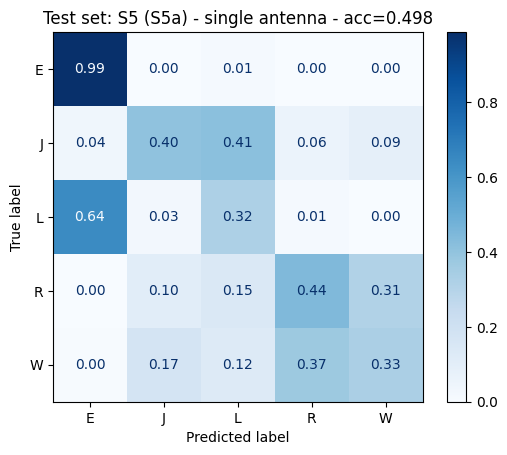

S6 (S6a, S6b): n=2092, loss=1.1101, acc=0.5057


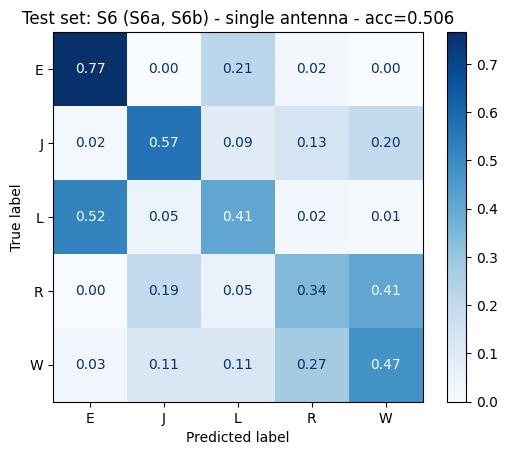

S7 (S7a): n=1028, loss=1.1600, acc=0.5146


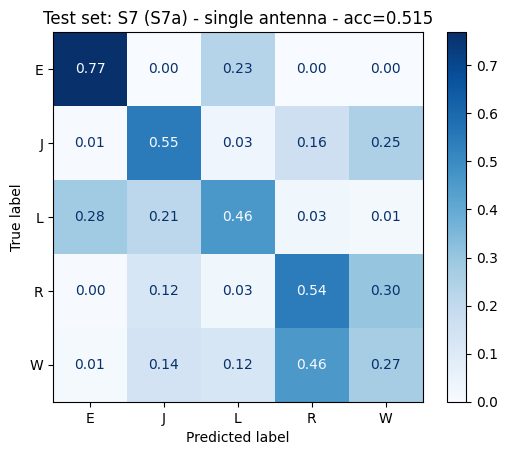

In [19]:
def evaluate_environment_group(group_name, member_envs):
    mask = np.isin(envs_test, member_envs)   # windows belonging to any environment in this group
    X_grp, y_grp = X_test[mask], y_test[mask]
    if len(y_grp) == 0:
        print(f"{group_name}: no windows found, skipping")
        return None

    grp_dataset = DopplerDataset(X_grp, y_grp)
    grp_dataloader = DataLoader(grp_dataset, batch_size=BATCH_SIZE, shuffle=False)

    loss, acc = run_epoch(grp_dataloader, model, criterion, optimizer=None)
    print(f"{group_name} ({', '.join(member_envs)}): n={len(y_grp)}, loss={loss:.4f}, acc={acc:.4f}")

    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for batch_x, batch_y in grp_dataloader:
            batch_x = batch_x.to(device)
            logits = model(batch_x)
            preds.append(logits.argmax(dim=1).cpu())
            labels.append(batch_y)
    preds = torch.cat(preds).numpy()
    labels = torch.cat(labels).numpy()

    # labels=range(len(ACTIVITIES)) keeps the matrix 5x5 even if this group has 0 samples of some class;
    # normalize="true" keeps every cell in [0, 1] regardless of how many windows this group has
    cm = confusion_matrix(labels, preds, labels=list(range(len(ACTIVITIES))), normalize="true")
    disp = ConfusionMatrixDisplay(cm, display_labels=ACTIVITIES)
    disp.plot(cmap="Blues", values_format=".2f")
    plt.title(f"Test set: {group_name} ({', '.join(member_envs)}) - single antenna - acc={acc:.3f}")
    plt.show()
    return acc


per_group_acc = {}
for group_name, member_envs in sorted(test_groups.items()):
    per_group_acc[group_name] = evaluate_environment_group(group_name, member_envs)


## 8. Recap: what section 9 adds

Sections 6 and 7 above treat every window as an independent sample, regardless of which of the 4 antennas it came from -- this matches how the SHARP paper **trains** its classifier (section 4.1: "the Doppler traces collected from the different antennas are used without any distinction among them"). But at **evaluation** time, the paper does one more thing (section 4.2): for a given real time window, it collects the classifier's 4 independent per-antenna predictions and **fuses** them into a single, final prediction, since combining several noisy "views" of the same event is generally more reliable than trusting just one antenna. The dataset gives us the 4 antennas' Doppler traces *separately* (`stream_0` ... `stream_3`), not pre-fused -- this fusion step is exactly what we implement next.


## 9. Multi-antenna decision fusion (all test environments together)

**How the fusion works.** For each test window we already computed a `group_id` in section 2 (e.g. `"S4a_J2_17"`): all windows that share the same `group_id` are the *same* real time window, recorded simultaneously by (up to) 4 different antennas. To fuse them:

1. Run the trained model on every test window and convert its output logits into class **probabilities** with `softmax` (instead of just taking the single most likely class).
2. For every `group_id`, **average** the probability vectors of all the antennas available for that time window (2, 3, or 4, depending on the recording).
3. The fused prediction is the class with the highest *averaged* probability.

This is a simple form of "soft" decision fusion (as opposed to, e.g., majority voting on the hard per-antenna predictions): it lets antennas that are very confident weigh in more than antennas that are unsure, without needing anything fancier than an average. The paper's own decision-fusion rule (section 4.2) isn't detailed in the slides available for this project, so this is a reasonable, simple, well-known choice consistent with their general idea, not a byte-for-byte reproduction.


In [20]:
def get_probabilities(dataloader, model):
    """Run the model over an (unshuffled) dataloader and return, in the same sample order:
    - probs: softmax probabilities, shape (N, num_classes)
    - labels: true class indices, shape (N,)
    """
    model.eval()
    all_probs, all_labels = [], []
    with torch.no_grad():
        for batch_x, batch_y in dataloader:
            batch_x = batch_x.to(device)
            logits = model(batch_x)
            probs = torch.softmax(logits, dim=1)  # turn raw logits into per-class probabilities that sum to 1
            all_probs.append(probs.cpu())
            all_labels.append(batch_y)
    return torch.cat(all_probs).numpy(), torch.cat(all_labels).numpy()


def fuse_by_group(probs, labels, sample_groups):
    """Average the per-antenna probability vectors that share the same group id (i.e. the same real
    time window, observed by up to 4 antennas), then take the most likely class as the fused prediction.
    Returns one fused prediction and one true label PER GROUP (so fewer rows than the input, one per
    real time window instead of one per antenna).
    """
    fused_preds, fused_labels = [], []
    for g in np.unique(sample_groups):           # one iteration per real time window (i.e. per group id)
        idx = sample_groups == g                 # every antenna's row for this exact time window
        avg_probs = probs[idx].mean(axis=0)      # soft fusion: average probabilities across the available antennas
        fused_preds.append(avg_probs.argmax())   # fused prediction = class with the highest averaged probability
        fused_labels.append(labels[idx][0])      # all rows in the same group share the same true label by construction
    return np.array(fused_preds), np.array(fused_labels)


Single-antenna test accuracy (section 6): 0.5125  (n=10308 antenna-level windows)
Fused (multi-antenna) test accuracy:       0.6147  (n=2577 real time windows)


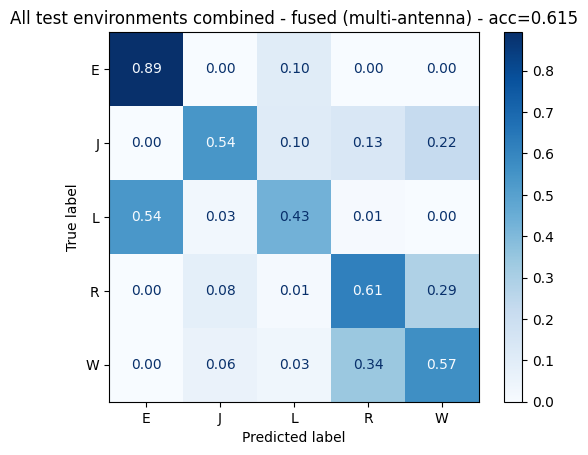

In [21]:
probs_test, labels_test = get_probabilities(test_dataloader, model)  # test_dataloader has shuffle=False, so this lines up with groups_test
fused_preds, fused_labels = fuse_by_group(probs_test, labels_test, groups_test)
fused_acc = accuracy_score(fused_labels, fused_preds)

print(f"Single-antenna test accuracy (section 6): {test_acc:.4f}  (n={len(y_test)} antenna-level windows)")
print(f"Fused (multi-antenna) test accuracy:       {fused_acc:.4f}  (n={len(fused_labels)} real time windows)")

cm = confusion_matrix(fused_labels, fused_preds, labels=list(range(len(ACTIVITIES))), normalize="true")
disp = ConfusionMatrixDisplay(cm, display_labels=ACTIVITIES)
disp.plot(cmap="Blues", values_format=".2f")
plt.title(f"All test environments combined - fused (multi-antenna) - acc={fused_acc:.3f}")
plt.show()


## 10. Multi-antenna decision fusion (grouped by measurement set)

Same idea as section 7, but using the fused (multi-antenna) predictions from section 9 instead of single-antenna ones.


.placeholder: no windows found, skipping
S2 (S2a, S2b): fused_acc=0.6264 (n_time_windows=704, n_antenna_windows=2816)


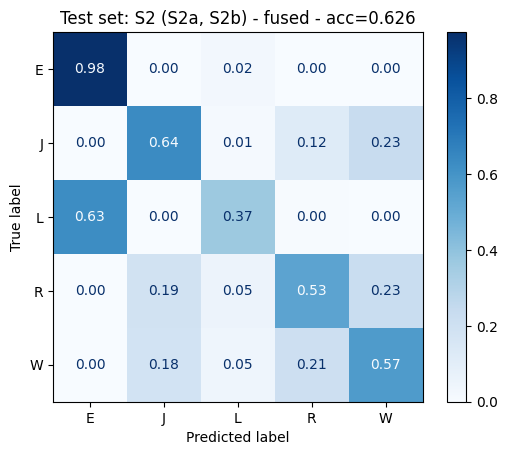

S3 (S3a): fused_acc=0.6884 (n_time_windows=276, n_antenna_windows=1104)


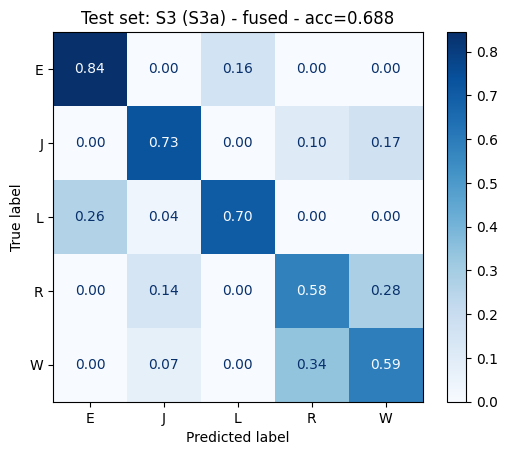

S4 (S4a, S4b): fused_acc=0.5809 (n_time_windows=544, n_antenna_windows=2176)


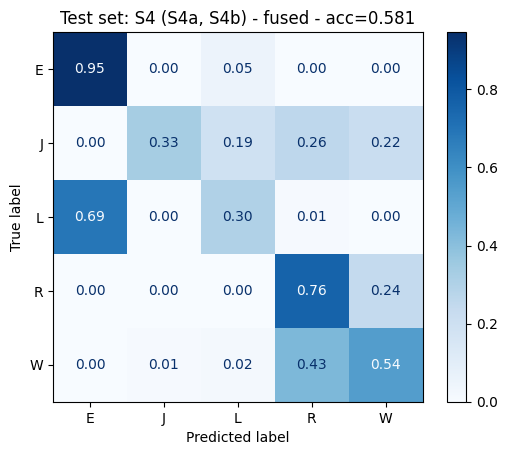

S5 (S5a): fused_acc=0.5751 (n_time_windows=273, n_antenna_windows=1092)


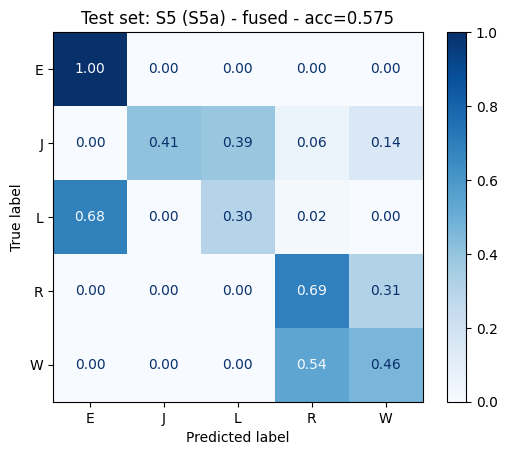

S6 (S6a, S6b): fused_acc=0.5793 (n_time_windows=523, n_antenna_windows=2092)


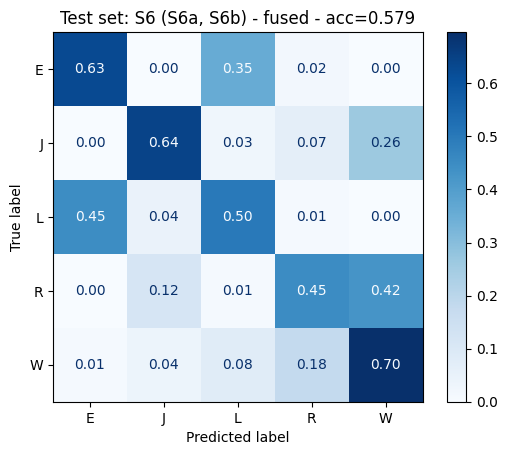

S7 (S7a): fused_acc=0.6887 (n_time_windows=257, n_antenna_windows=1028)


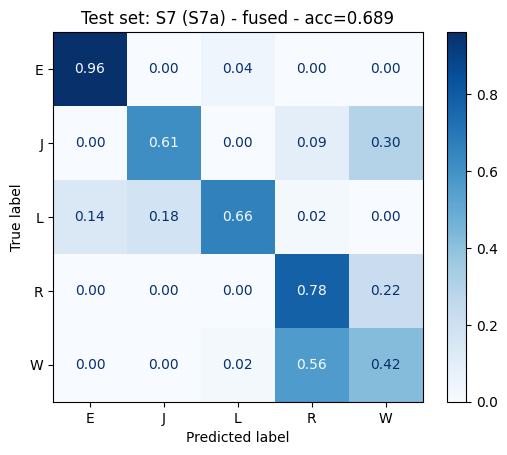

In [22]:
def evaluate_environment_group_fused(group_name, member_envs):
    mask = np.isin(envs_test, member_envs)       # windows belonging to any environment in this group
    if mask.sum() == 0:
        print(f"{group_name}: no windows found, skipping")
        return None

    X_grp, y_grp, groups_grp = X_test[mask], y_test[mask], groups_test[mask]
    grp_dataset = DopplerDataset(X_grp, y_grp)
    grp_dataloader = DataLoader(grp_dataset, batch_size=BATCH_SIZE, shuffle=False)  # shuffle=False keeps alignment with groups_grp

    probs, labels = get_probabilities(grp_dataloader, model)
    fused_preds, fused_labels = fuse_by_group(probs, labels, groups_grp)
    fused_acc = accuracy_score(fused_labels, fused_preds)
    print(f"{group_name} ({', '.join(member_envs)}): fused_acc={fused_acc:.4f} "
          f"(n_time_windows={len(fused_labels)}, n_antenna_windows={len(y_grp)})")

    cm = confusion_matrix(fused_labels, fused_preds, labels=list(range(len(ACTIVITIES))), normalize="true")
    disp = ConfusionMatrixDisplay(cm, display_labels=ACTIVITIES)
    disp.plot(cmap="Blues", values_format=".2f")
    plt.title(f"Test set: {group_name} ({', '.join(member_envs)}) - fused - acc={fused_acc:.3f}")
    plt.show()
    return fused_acc


per_group_fused_acc = {}
for group_name, member_envs in sorted(test_groups.items()):
    per_group_fused_acc[group_name] = evaluate_environment_group_fused(group_name, member_envs)


## 11. Possible next steps

This notebook uses the simplest possible setup: 5 core activities, a single baseline model, a configurable train/test split by environment, and simple probability-averaging decision fusion across antennas. Natural extensions, in line with the project slides' challenges:

- **Try different `TRAIN_ENVS` / `TEST_ENVS` combinations**: e.g. train on `S1` only (as in the paper) vs. training on several environments at once, and compare test accuracy on the remaining ones.
- **More activities**: include the extra classes available in some environments (`C`, `S`, `H`).
- **Different fusion rules**: compare the probability-averaging fusion in section 9/10 against majority voting on the hard per-antenna predictions, or a confidence-weighted average.


## 12. A more complex model: Supervised Contrastive Learning

The baseline is trained with plain cross-entropy on **one** measurement set (`S1`) and then evaluated on completely
unseen environments, people and days. As the per-environment confusion matrices in Section 7 show, accuracy drops on
the unseen sets: this is a classic **domain-shift** problem, and it is the exact difficulty raised in the project
slides (*"Different environments modify the signal differently"*, *"Generalizing to different subjects is challenging"*,
*"Contrastive/self-supervised approach?"*).

We follow that hint and implement **Supervised Contrastive Learning (SupCon)** [Khosla et al., NeurIPS 2020]. The idea
is to change *what* the network optimises:

1. **Representation learning (contrastive).** Instead of predicting the class directly, we first train an **encoder**
   to produce an embedding where two windows of the *same* activity are pulled close together and windows of
   *different* activities are pushed apart — **no matter which environment/person they came from**. Because the loss
   only cares about *activity identity*, the encoder is encouraged to ignore environment-specific nuisances, which is
   exactly what we need for generalization.
2. **Classification (linear probe).** We then freeze the encoder and fit a tiny linear classifier on top of the frozen
   embeddings. If the representation is good, even a linear layer generalises better to unseen environments than the
   end-to-end baseline.

To create the "same activity, different nuisance" pairs the contrastive loss needs, we use **data augmentation** that
perturbs the signal without changing the activity (a light form of *domain randomization*). We also add an optional
**end-to-end fine-tuning** step and a **t-SNE visualization** of the learned space.

This section is self-contained: it defines its own encoder and only *reuses* the data/utilities already built above.

In [23]:
# ---- Setup and hyper-parameters for the contrastive stage -------------------
import copy
import torch.nn.functional as F                 # functional API: used for L2-normalisation of the embeddings
from torch.utils.data import TensorDataset       # lets us wrap the pre-computed feature tensors as a Dataset

# Re-seed here so this section is reproducible on its own, independent of how
# many random numbers the earlier cells happened to draw.
torch.manual_seed(seed)
np.random.seed(seed)

FEATURE_DIM = 128     # size of the representation ("backbone" output) the encoder produces
PROJ_DIM    = 128     # size of the projection-head output; the contrastive loss lives in this space
TEMPERATURE = 0.07    # SupCon temperature: smaller -> sharper contrast. 0.07 is the value used in the paper
CL_EPOCHS   = 30      # upper bound on contrastive pre-training epochs (early stopping usually stops earlier)
CL_PATIENCE = 7       # early-stopping patience on the validation contrastive loss
CL_LR       = 1e-4    # Adam learning rate for the contrastive stage

# Pull the baseline results from sections 6-7 so we can compare against them at the end.
# globals().get(...) keeps this cell runnable even if those exact cells were not re-run in this session.
baseline_test_acc      = globals().get("test_acc", None)
baseline_per_group_acc = dict(globals().get("per_group_acc", {}))
print("Baseline overall test accuracy:", baseline_test_acc)
print("Baseline per-group accuracy   :", baseline_per_group_acc)

Baseline overall test accuracy: 0.5125145518044237
Baseline per-group accuracy   : {'.placeholder': None, 'S2': 0.5088778409090909, 'S3': 0.5588768115942029, 'S4': 0.5064338235294118, 'S5': 0.4981684981684982, 'S6': 0.505736137667304, 'S7': 0.5145914396887159}


### 12.1 Data augmentation (creating two "views" of each window)

Contrastive learning needs, for every window, a pair of *augmented views* that keep the **activity** intact but change
details that a good classifier should ignore. On a Doppler spectrogram, activity information lives in the overall
*pattern* of energy over time and velocity, not in the exact amplitude or in one specific time/velocity band. So we
use augmentations that mimic environment/measurement variability:

- **Amplitude scaling** — different rooms/distances reflect the signal with different strength.
- **Additive Gaussian noise** — measurement noise differs across setups.
- **Circular time shift** — the activity is the same regardless of *where* in the ~2 s window it starts.
- **Time & Doppler masking** (SpecAugment-style) — zero a random band along time and along velocity so the encoder
  cannot rely on any single region and must use the whole pattern.

All operations are vectorised on the GPU and applied to a whole batch at once.

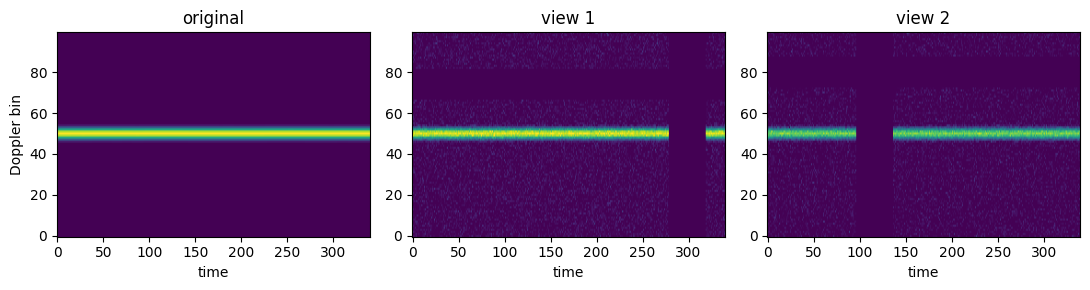

In [24]:
def augment(x, noise_std=0.05, max_time_shift=40, time_mask=40, dopp_mask=15, scale_range=(0.8, 1.2)):
    """Return an augmented view of a batch of Doppler windows.

    Args:
        x: float tensor of shape (B, 1, WIN_LEN, N_DOPPLER_BINS) on `device`.
    The activity label is preserved; only nuisance factors are perturbed.
    """
    B, _, T, D = x.shape

    # 1) per-sample amplitude scaling (each window multiplied by its own random gain)
    scale = torch.empty(B, 1, 1, 1, device=x.device).uniform_(*scale_range)
    out = x * scale

    # 2) additive Gaussian noise
    out = out + torch.randn_like(out) * noise_std

    # 3) circular shift along the time axis (dim=2) -> temporal translation invariance
    shift = int(torch.randint(-max_time_shift, max_time_shift + 1, (1,)).item())
    out = torch.roll(out, shifts=shift, dims=2)

    # 4) SpecAugment-style masking: build 0/1 masks and multiply (no in-place ops, autograd-safe).
    #    A random contiguous band along time is zeroed...
    t0 = int(torch.randint(0, max(1, T - time_mask), (1,)).item())
    tmask = torch.ones(1, 1, T, 1, device=x.device)
    tmask[:, :, t0:t0 + time_mask, :] = 0.0
    #    ...and a random contiguous band along the Doppler (velocity) bins.
    d0 = int(torch.randint(0, max(1, D - dopp_mask), (1,)).item())
    dmask = torch.ones(1, 1, 1, D, device=x.device)
    dmask[:, :, :, d0:d0 + dopp_mask] = 0.0

    return out * tmask * dmask


# quick visual sanity check: original window vs two augmented views.
# All three panels share the ORIGINAL window's colour scale (vmin/vmax) so the views are
# directly comparable and the additive noise doesn't stretch each panel's colormap on its own.
_dbg_x, _ = next(iter(train_dataloader))
_dbg_x = _dbg_x[:1].to(device)                       # take a single window
_views = [_dbg_x, augment(_dbg_x), augment(_dbg_x)]
_vmin, _vmax = float(_dbg_x.min()), float(_dbg_x.max())
fig, axs = plt.subplots(1, 3, figsize=(11, 3))
for ax, v, title in zip(axs, _views, ["original", "view 1", "view 2"]):
    ax.imshow(v[0, 0].detach().cpu().T, aspect="auto", origin="lower",
              cmap="viridis", vmin=_vmin, vmax=_vmax)   # shared scale -> comparable, not washed out
    ax.set_title(title); ax.set_xlabel("time")
axs[0].set_ylabel("Doppler bin")
plt.tight_layout(); plt.show()
plt.close(fig)

### 12.2 The encoder and the projection head

The **encoder** is a deeper, batch-normalised evolution of the baseline's Inception block. Three key differences make
it more expressive while staying small:

- **Batch normalisation** after every convolution — stabilises training and helps generalization.
- **A second convolutional stage** that downsamples further, so the network sees a larger receptive field.
- **Global average pooling** instead of the baseline's giant `flatten -> dense`: it produces a fixed-size
  `FEATURE_DIM` vector with far fewer parameters and is naturally more robust to shifts.

The **projection head** is a small MLP used *only during contrastive training*. The SupCon paper shows it is better to
apply the contrastive loss on a projected, L2-normalised embedding `z` (on the unit hypersphere) and then **throw the
head away**, using the encoder output `h` for the actual classification. So we keep two outputs: `h` (for the
classifier) and `z` (for the loss).

In [25]:
class InceptionBlock(nn.Module):
    """Three parallel branches (pool / strided conv / deeper conv) concatenated on the channel axis.
    All branches halve the spatial size to (WIN_LEN/2, N_DOPPLER_BINS/2) so they can be concatenated."""
    def __init__(self, in_ch=1):
        super().__init__()
        self.branch1 = nn.MaxPool2d(kernel_size=2, stride=2)                      # -> in_ch channels
        self.branch2 = nn.Sequential(                                             # -> 16 channels
            nn.Conv2d(in_ch, 16, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(16), nn.ReLU(),
        )
        self.branch3 = nn.Sequential(                                             # -> 24 channels
            nn.Conv2d(in_ch, 16, kernel_size=1), nn.BatchNorm2d(16), nn.ReLU(),
            nn.Conv2d(16, 24, kernel_size=3, stride=2, padding=1), nn.BatchNorm2d(24), nn.ReLU(),
        )

    def forward(self, x):
        return torch.cat([self.branch1(x), self.branch2(x), self.branch3(x)], dim=1)  # in_ch + 16 + 24 channels


class ContrastiveEncoder(nn.Module):
    """Maps a (B, 1, 340, 100) window to a FEATURE_DIM-dimensional representation h."""
    def __init__(self, feature_dim=FEATURE_DIM):
        super().__init__()
        self.feature_dim = feature_dim
        self.inception = InceptionBlock(in_ch=1)                                  # -> (B, 41, 170, 50)
        self.reduce = nn.Sequential(                                              # mix the 41 branch channels -> 32
            nn.Conv2d(1 + 16 + 24, 32, kernel_size=1), nn.BatchNorm2d(32), nn.ReLU(),
        )
        self.stage2 = nn.Sequential(                                              # deeper, downsampling stage
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, feature_dim, kernel_size=3, stride=2, padding=1), nn.BatchNorm2d(feature_dim), nn.ReLU(),
        )
        self.gap = nn.AdaptiveAvgPool2d(1)                                        # -> (B, feature_dim, 1, 1)

    def forward(self, x):
        x = self.inception(x)
        x = self.reduce(x)
        x = self.stage2(x)
        x = self.gap(x).flatten(1)                                                # -> (B, feature_dim)
        return x


class ProjectionHead(nn.Module):
    """Small MLP used only by the contrastive loss; outputs an L2-normalised vector (a point on the unit sphere)."""
    def __init__(self, in_dim=FEATURE_DIM, hidden=PROJ_DIM, out_dim=PROJ_DIM):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(), nn.Linear(hidden, out_dim))

    def forward(self, x):
        return F.normalize(self.net(x), dim=1)   # unit-norm so the dot product below equals the cosine similarity


# instantiate and sanity-check shapes / parameter count
encoder   = ContrastiveEncoder(FEATURE_DIM).to(device)
proj_head = ProjectionHead(FEATURE_DIM, PROJ_DIM, PROJ_DIM).to(device)

with torch.no_grad():
    _dummy = torch.zeros(4, 1, WIN_LEN, N_DOPPLER_BINS).to(device)
    _h = encoder(_dummy)
    _z = proj_head(_h)
    print("encoder output h:", tuple(_h.shape), "| projection z:", tuple(_z.shape),
          "| |z| =", _z.norm(dim=1).mean().item())   # |z| should be ~1.0

n_params = sum(p.numel() for p in encoder.parameters()) + sum(p.numel() for p in proj_head.parameters())
print(f"Contrastive model trainable parameters: {n_params:,}  (baseline was ~128,535)")

encoder output h: (4, 128) | projection z: (4, 128) | |z| = 1.0
Contrastive model trainable parameters: 130,952  (baseline was ~128,535)


### 12.3 The Supervised Contrastive (SupCon) loss

For a batch of L2-normalised embeddings, the SupCon loss makes each **anchor** attract *every other sample sharing its
label* (its positives) and repel everything else, using a softmax over cosine similarities scaled by the temperature:

$$\mathcal{L} = \sum_{i} \frac{-1}{|P(i)|} \sum_{p \in P(i)} \log \frac{\exp(z_i \cdot z_p / \tau)}{\sum_{a \neq i} \exp(z_i \cdot z_a / \tau)}$$

where `P(i)` is the set of samples with the same label as `i` (excluding `i` itself). Unlike SimCLR, this uses the
**labels**, so all same-activity windows in the batch — even from different files/environments — become positives.
That is what turns generic contrastive learning into an *environment-invariant activity* representation.

In [26]:
def supcon_loss(features, labels, temperature=TEMPERATURE):
    """Supervised Contrastive loss (Khosla et al., 2020).

    Args:
        features: (B, d) tensor, assumed already L2-normalised (as produced by ProjectionHead).
        labels:   (B,) integer class labels.
    """
    device_ = features.device
    B = features.shape[0]

    # cosine similarity matrix scaled by temperature; subtract the row-max for numerical stability
    sim = features @ features.t() / temperature
    sim = sim - sim.max(dim=1, keepdim=True)[0].detach()

    labels = labels.contiguous().view(-1, 1)
    same_label = (labels == labels.t()).float().to(device_)     # 1 where two samples share the label
    self_mask  = torch.eye(B, device=device_)                   # 1 on the diagonal (a sample vs itself)
    pos_mask   = same_label * (1.0 - self_mask)                 # positives = same label, excluding self

    # denominator sums over all samples except the anchor itself
    exp_sim  = torch.exp(sim) * (1.0 - self_mask)
    log_prob = sim - torch.log(exp_sim.sum(dim=1, keepdim=True) + 1e-12)

    # average the log-probability over the positives of each anchor
    pos_count = pos_mask.sum(dim=1)
    mean_log_prob_pos = (pos_mask * log_prob).sum(dim=1) / pos_count.clamp(min=1.0)

    # only anchors that actually have at least one positive contribute (always true when we use two views)
    loss = -mean_log_prob_pos
    return loss[pos_count > 0].mean()


# sanity check: perfectly separated clusters should give a very low loss
_f = F.normalize(torch.tensor([[1., 0.], [1., 0.], [0., 1.], [0., 1.]]), dim=1)
_l = torch.tensor([0, 0, 1, 1])
print("SupCon sanity loss (well separated):", round(supcon_loss(_f, _l, 0.07).item(), 4))

SupCon sanity loss (well separated): 0.0


### 12.4 Contrastive pre-training

We now train the encoder + projection head on the **training environments only** (same `S1`-based split as the
baseline, so the comparison is fair). Each batch is turned into two augmented views; the SupCon loss then organises the
embedding space. We monitor the loss on the validation split and keep the best encoder weights (early stopping).

In [ ]:
def run_supcon_epoch(dataloader, encoder, head, optimizer=None):
    """One epoch of contrastive training (optimizer given) or evaluation (optimizer=None)."""
    is_train = optimizer is not None
    encoder.train(); head.train()
    if not is_train:
        encoder.eval(); head.eval()

    total_loss, n = 0.0, 0
    with torch.set_grad_enabled(is_train):
        for batch_x, batch_y in dataloader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)

            # two independent augmented views of the same batch, stacked along the batch axis
            views  = torch.cat([augment(batch_x), augment(batch_x)], dim=0)
            labels = torch.cat([batch_y, batch_y], dim=0)          # both views keep the original label

            z = head(encoder(views))                               # (2B, PROJ_DIM), L2-normalised
            loss = supcon_loss(z, labels, TEMPERATURE)

            if is_train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()

            total_loss += loss.item() * batch_x.size(0); n += batch_x.size(0)
    return total_loss / n


cl_optimizer = torch.optim.Adam(
    list(encoder.parameters()) + list(proj_head.parameters()), lr=CL_LR, weight_decay=1e-4
)

cl_train_losses, cl_val_losses = [], []
best_cl_val = float("inf"); cl_no_improve = 0
best_encoder_state, best_head_state = None, None

for epoch in tqdm(range(CL_EPOCHS)):
    tr = run_supcon_epoch(train_dataloader, encoder, proj_head, cl_optimizer)   # train
    va = run_supcon_epoch(val_dataloader,   encoder, proj_head, optimizer=None)  # validate
    cl_train_losses.append(tr); cl_val_losses.append(va)
    print(f"[contrastive] epoch {epoch+1}/{CL_EPOCHS} - train_loss: {tr:.4f} - val_loss: {va:.4f}")

    if va < best_cl_val:                                    # snapshot the best (lowest val loss) weights
        best_cl_val = va; cl_no_improve = 0
        best_encoder_state = {k: v.detach().cpu().clone() for k, v in encoder.state_dict().items()}
        best_head_state    = {k: v.detach().cpu().clone() for k, v in proj_head.state_dict().items()}
    else:
        cl_no_improve += 1
    if cl_no_improve >= CL_PATIENCE:
        print(f"Early stopping contrastive pre-training at epoch {epoch+1}.")
        break

# restore the best encoder (the projection head has done its job and won't be needed for classification)
if best_encoder_state is not None:
    encoder.load_state_dict(best_encoder_state)
    proj_head.load_state_dict(best_head_state)
    print(f"Restored best encoder (val contrastive loss = {best_cl_val:.4f}).")

plt.figure(figsize=(6, 4))
plt.plot(cl_train_losses, label="train"); plt.plot(cl_val_losses, label="val")
plt.title("Contrastive (SupCon) loss"); plt.xlabel("epoch"); plt.legend(); plt.tight_layout(); plt.show()

  3%|▎         | 1/30 [00:06<03:10,  6.55s/it]

[contrastive] epoch 1/30 - train_loss: 4.6725 - val_loss: 4.7299


  7%|▋         | 2/30 [00:12<02:57,  6.35s/it]

[contrastive] epoch 2/30 - train_loss: 4.5493 - val_loss: 4.5102


 10%|█         | 3/30 [00:19<02:52,  6.38s/it]

...

 47%|████▋     | 14/30 [01:28<01:38,  6.17s/it]

[contrastive] epoch 14/30 - train_loss: 4.4676 - val_loss: 4.4858


 50%|█████     | 15/30 [01:34<01:32,  6.18s/it]

[contrastive] epoch 15/30 - train_loss: 4.4543 - val_loss: 4.4323


 50%|█████     | 15/30 [01:40<01:40,  6.69s/it]

### 12.5 Linear evaluation (linear probe)

Standard protocol to measure the *quality of a representation*: **freeze** the encoder, pre-compute the embeddings once,
and train only a single `Linear` layer on top with ordinary cross-entropy. If the contrastive representation truly
captured activity structure, this linear classifier should already generalise well to the unseen environments.

In [ ]:
@torch.no_grad()
def extract_features(encoder, dataset, batch_size=256):
    """Run the frozen encoder over a dataset and return (features, labels) tensors, kept in the original order."""
    encoder.eval()
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    feats, labels = [], []
    for bx, by in loader:
        feats.append(encoder(bx.to(device)).cpu())
        labels.append(by)
    return torch.cat(feats), torch.cat(labels)


# pre-compute embeddings for the three splits
feat_train, ytr = extract_features(encoder, train_dataset)
feat_val,   yva = extract_features(encoder, val_dataset)
feat_test,  yte = extract_features(encoder, test_dataset)

# standardise features using train statistics (helps the linear layer converge)
mu = feat_train.mean(0, keepdim=True); sd = feat_train.std(0, keepdim=True) + 1e-6
ftr, fva, fte = (feat_train - mu) / sd, (feat_val - mu) / sd, (feat_test - mu) / sd

# wrap the feature tensors as datasets and reuse the SAME run_epoch / criterion as the baseline
tr_loader = DataLoader(TensorDataset(ftr, ytr), batch_size=256, shuffle=True)
va_loader = DataLoader(TensorDataset(fva, yva), batch_size=256, shuffle=False)

linear = nn.Linear(FEATURE_DIM, len(ACTIVITIES)).to(device)
probe_optimizer = torch.optim.Adam(linear.parameters(), lr=1e-4, weight_decay=1e-4)

best_probe_val = float("inf"); probe_no_improve = 0; best_probe_state = None
for epoch in range(100):                                   # generous budget; early stopping ends it early
    tr_loss, tr_acc = run_epoch(tr_loader, linear, criterion, probe_optimizer)
    va_loss, va_acc = run_epoch(va_loader, linear, criterion, optimizer=None)
    if va_loss < best_probe_val:
        best_probe_val = va_loss; probe_no_improve = 0
        best_probe_state = {k: v.detach().cpu().clone() for k, v in linear.state_dict().items()}
    else:
        probe_no_improve += 1
    if probe_no_improve >= 10:
        break
linear.load_state_dict(best_probe_state)
print(f"Linear probe trained. Best val loss={best_probe_val:.4f}, val acc={va_acc:.4f} (epoch {epoch+1}).")

### 12.6 Test-set evaluation and comparison with the baseline

We now evaluate the frozen-encoder + linear-probe model on the unseen environments, both overall and grouped by
measurement set (`S2`...`S7`), and put the numbers side-by-side with the baseline from Sections 6-7.

In [ ]:
# overall test predictions and accuracy
linear.eval()
with torch.no_grad():
    cl_test_logits = linear(fte.to(device))
cl_test_preds = cl_test_logits.argmax(1).cpu().numpy()
yte_np = yte.numpy()
cl_test_acc = accuracy_score(yte_np, cl_test_preds)
print(f"Contrastive overall test accuracy: {cl_test_acc:.4f}"
      + (f"   (baseline: {baseline_test_acc:.4f})" if baseline_test_acc is not None else ""))

# overall confusion matrix
cm = confusion_matrix(yte_np, cl_test_preds, labels=list(range(len(ACTIVITIES))), normalize="true")
ConfusionMatrixDisplay(cm, display_labels=ACTIVITIES).plot(cmap="Blues", values_format=".2f")
plt.title(f"Contrastive model - all test environments (acc={cl_test_acc:.3f})"); plt.show()

# per measurement-set group accuracy (reuses test_groups / envs_test built in Section 7)
cl_per_group_acc = {}
for group_name, member_envs in sorted(test_groups.items()):
    mask = np.isin(envs_test, member_envs)
    if mask.sum() == 0:
        continue
    cl_per_group_acc[group_name] = accuracy_score(yte_np[mask], cl_test_preds[mask])
    print(f"  {group_name} ({', '.join(member_envs)}): n={int(mask.sum())}, acc={cl_per_group_acc[group_name]:.4f}")

# side-by-side bar chart: baseline vs contrastive, per group and overall
groups = sorted(cl_per_group_acc.keys())
labels_x = groups + ["Overall"]
base_vals = [baseline_per_group_acc.get(g) if baseline_per_group_acc.get(g) is not None else 0.0 for g in groups]
base_vals += [baseline_test_acc if baseline_test_acc is not None else 0.0]
cl_vals   = [cl_per_group_acc[g] for g in groups] + [cl_test_acc]

x = np.arange(len(labels_x)); w = 0.38
plt.figure(figsize=(10, 4))
plt.bar(x - w/2, base_vals, width=w, label="baseline (Marco)")
plt.bar(x + w/2, cl_vals,  width=w, label="contrastive (Francesco)")
plt.xticks(x, labels_x); plt.ylabel("accuracy"); plt.ylim(0, 1)
plt.title("Cross-environment accuracy: baseline vs contrastive")
plt.legend(); plt.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

### 12.7 (Optional) End-to-end fine-tuning

The linear probe deliberately keeps the encoder frozen to *measure the representation*. In practice we can usually
squeeze out a bit more accuracy by **unfreezing the encoder** and fine-tuning the whole network (encoder +
classifier) end-to-end with a **small** learning rate — small enough not to destroy the contrastive features. We start
from a copy of the pre-trained encoder so the linear-probe results above stay intact.

In [ ]:
class ClassifierModel(nn.Module):
    """Encoder + a linear classification head, trainable end-to-end."""
    def __init__(self, encoder, num_classes):
        super().__init__()
        self.encoder = encoder
        self.head = nn.Linear(encoder.feature_dim, num_classes)

    def forward(self, x):
        return self.head(self.encoder(x))


ft_model = ClassifierModel(copy.deepcopy(encoder), len(ACTIVITIES)).to(device)
ft_optimizer = torch.optim.Adam(ft_model.parameters(), lr=1e-4)   # small LR: gently adapt the pre-trained features

best_ft_val = float("inf"); ft_no_improve = 0; best_ft_state = None
for epoch in tqdm(range(20)):
    tr_loss, tr_acc = run_epoch(train_dataloader, ft_model, criterion, ft_optimizer)
    va_loss, va_acc = run_epoch(val_dataloader,   ft_model, criterion, optimizer=None)
    print(f"[fine-tune] epoch {epoch+1} - train_acc: {tr_acc:.4f} - val_acc: {va_acc:.4f}")
    if va_loss < best_ft_val:
        best_ft_val = va_loss; ft_no_improve = 0
        best_ft_state = {k: v.detach().cpu().clone() for k, v in ft_model.state_dict().items()}
    else:
        ft_no_improve += 1
    if ft_no_improve >= 5:
        print(f"Early stopping fine-tuning at epoch {epoch+1}."); break
if best_ft_state is not None:
    ft_model.load_state_dict(best_ft_state)

ft_test_loss, ft_test_acc = run_epoch(test_dataloader, ft_model, criterion, optimizer=None)
print(f"Fine-tuned overall test accuracy: {ft_test_acc:.4f}"
      + (f"   (linear probe: {cl_test_acc:.4f}, baseline: {baseline_test_acc:.4f})"
         if baseline_test_acc is not None else f"   (linear probe: {cl_test_acc:.4f})"))

### 12.8 Visualising the learned representation (t-SNE)

To *see* whether the encoder learned an environment-invariant activity space, we project a random subset of the test
embeddings to 2-D with t-SNE and colour them two ways:

- **by activity** — if the representation is good, we expect clean, well-separated clusters;
- **by environment group** — if the representation is environment-*invariant*, the colours here should be **mixed
  inside** each activity cluster (the encoder is not separating rooms, only activities).

In [ ]:
from sklearn.manifold import TSNE

n_show = min(2000, feat_test.shape[0])                        # t-SNE is slow, so subsample
sel = np.random.choice(feat_test.shape[0], size=n_show, replace=False)
emb2d = TSNE(n_components=2, init="pca", perplexity=30, random_state=seed).fit_transform(feat_test[sel].numpy())

group_of_test = np.array([env_group(e) for e in envs_test])   # measurement-set group per test window
fig, axs = plt.subplots(1, 2, figsize=(13, 5))

# left: colour by activity
for i, act in enumerate(ACTIVITIES):
    m = yte_np[sel] == i
    axs[0].scatter(emb2d[m, 0], emb2d[m, 1], s=6, label=act)
axs[0].set_title("Test embeddings coloured by ACTIVITY"); axs[0].legend(markerscale=2)

# right: colour by environment group
for g in sorted(set(group_of_test[sel])):
    m = group_of_test[sel] == g
    axs[1].scatter(emb2d[m, 0], emb2d[m, 1], s=6, label=g)
axs[1].set_title("Same points coloured by ENVIRONMENT"); axs[1].legend(markerscale=2)
plt.tight_layout(); plt.show()

## 13. Sliding-window vs non-overlapping windowing

In Section 2, `build_dataset` cut every Doppler trace into **non-overlapping** windows: it advanced the `WIN_LEN`-sample window by exactly `WIN_LEN` samples each step (stride = window length), so consecutive windows never share any samples. That is the simplest choice, but it is also wasteful — an activity pattern that happens to straddle a window boundary gets split in half, and a trace of length `T` yields only `T // WIN_LEN` windows.

Here we redo the **exact same pipeline** (Sections 3-7: environment-based split, baseline model, training loop, per-measurement-set test evaluation) but build the dataset with a **sliding window**: the window advances by `STRIDE < WIN_LEN` samples, so consecutive windows **overlap**. With `STRIDE = WIN_LEN // 2` (50 % overlap) each trace yields roughly twice as many windows, giving denser temporal coverage and more (correlated) training examples — a form of data augmentation that is standard practice in Human Activity Recognition.

Everything else is held fixed (same `WIN_LEN`, same architecture, same `TRAIN_ENVS`/`TEST_ENVS`, same hyper-parameters), so the **only** variable is the windowing scheme. At the end we plot the sliding-window model's cross-environment accuracy next to the non-overlapping baseline from Sections 5-7.

**Two honest caveats about the comparison.**
- The window *length* is unchanged (`WIN_LEN = 340`), so the baseline architecture is reused as-is; only the *number* and *overlap* of the windows change. The test sets therefore contain a different number of windows, but they come from the same traces and the same held-out environments — i.e. the same underlying data.
- Overlapping windows are correlated. Because the test set is a **different set of environments** than train/val, there is no train↔test leakage. There is mild train↔val leakage (the random `train_test_split` can send two overlapping neighbours to opposite sides); that only affects when early stopping fires, not the reported test accuracy.

In [ ]:
# --- Rebuild the dataset with an OVERLAPPING (sliding) window --------------------
# Same logic as build_dataset (Section 2), but the window advances by `stride`
# samples instead of `win_len`, so consecutive windows overlap when stride < win_len.
def build_dataset_sliding(root_dir, activities=ACTIVITIES, win_len=WIN_LEN, stride=None):
    """Like build_dataset, but cuts each trace into windows that advance by `stride`
    samples. stride == win_len reproduces the original non-overlapping windows;
    stride < win_len produces overlapping windows (more, correlated samples).
    """
    if stride is None:
        stride = win_len  # default: non-overlapping, identical to build_dataset
    X_list, y_list, env_list = [], [], []
    for env in sorted(os.listdir(root_dir)):
        env_dir = os.path.join(root_dir, env)
        if not os.path.isdir(env_dir):
            continue
        for fname in sorted(os.listdir(env_dir)):
            parsed = parse_filename(fname)
            if parsed is None:
                continue
            _, label, _, _ = parsed
            if label not in activities:
                continue
            with open(os.path.join(env_dir, fname), "rb") as f:
                trace = pickle.load(f)  # shape (T, 100), T varies per file

            last_start = trace.shape[0] - win_len   # last index where a full window still fits
            if last_start < 0:
                continue
            starts = range(0, last_start + 1, stride)                 # 0, stride, 2*stride, ...
            windows = np.stack([trace[s: s + win_len] for s in starts])  # (n_win, win_len, 100)

            X_list.append(windows.astype(np.float32))
            y_list.extend([activities.index(label)] * len(windows))
            env_list.extend([env] * len(windows))

    X = np.concatenate(X_list, axis=0)[:, None, :, :]  # (N, 1, win_len, 100)
    y = np.array(y_list, dtype=np.int64)
    envs = np.array(env_list)
    return X, y, envs


STRIDE = WIN_LEN // 2   # 50% overlap; set STRIDE = WIN_LEN to recover non-overlapping windows
X_sw, y_sw, envs_sw = build_dataset_sliding(DATASET_ROOT, stride=STRIDE)
print(f"Sliding window (stride={STRIDE}, {100*(1-STRIDE/WIN_LEN):.0f}% overlap)")
print("  sliding      X_sw shape:", X_sw.shape, f"({X_sw.shape[0]} windows)")
print("  non-overlap  X    shape:", X.shape,    f"({X.shape[0]} windows)")
print(f"  -> {X_sw.shape[0] / X.shape[0]:.2f}x as many windows")
for i, act in enumerate(ACTIVITIES):
    print(f"  {act}: {(y_sw == i).sum()} windows")

In [ ]:
# --- Same environment-based split as Section 3, applied to the sliding-window data ---
torch.manual_seed(seed)   # reproducible split + weight init for this section
np.random.seed(seed)

train_mask_sw = np.isin(envs_sw, TRAIN_ENVS)   # windows from the training environments
test_mask_sw  = np.isin(envs_sw, TEST_ENVS)    # windows from the held-out environments

X_trainval_sw, y_trainval_sw = X_sw[train_mask_sw], y_sw[train_mask_sw]
X_test_sw,     y_test_sw      = X_sw[test_mask_sw],  y_sw[test_mask_sw]
envs_test_sw = envs_sw[test_mask_sw]           # keep each test window's environment for per-group evaluation

X_train_sw, X_val_sw, y_train_sw, y_val_sw = train_test_split(
    X_trainval_sw, y_trainval_sw, test_size=0.15, stratify=y_trainval_sw, random_state=seed
)

train_dataset_sw = DopplerDataset(X_train_sw, y_train_sw)
val_dataset_sw   = DopplerDataset(X_val_sw,   y_val_sw)
test_dataset_sw  = DopplerDataset(X_test_sw,  y_test_sw)
print("Sliding-window Train/Val/Test sizes:", len(train_dataset_sw), len(val_dataset_sw), len(test_dataset_sw))

train_dataloader_sw = DataLoader(train_dataset_sw, batch_size=BATCH_SIZE, shuffle=True)
val_dataloader_sw   = DataLoader(val_dataset_sw,   batch_size=BATCH_SIZE, shuffle=False)
test_dataloader_sw  = DataLoader(test_dataset_sw,  batch_size=BATCH_SIZE, shuffle=False)

In [ ]:
# --- Fresh baseline model, exactly the architecture from Section 4 ---
# WIN_LEN is unchanged, so BaselineHARNet is reused as-is (its flattened size still matches).
torch.manual_seed(seed)   # same weight initialisation as the non-overlapping baseline -> fair comparison
model_sw = BaselineHARNet().to(device)
optimizer_sw = torch.optim.Adam(model_sw.parameters(), lr=1e-4)
print(f"Trainable parameters: {count_parameters(model_sw):,}")

In [ ]:
# --- Training loop (same as Section 5), on the sliding-window data ---
train_losses_sw, val_losses_sw = [], []
train_accs_sw, val_accs_sw = [], []

best_val_loss_sw = float("inf")
epochs_without_improvement_sw = 0
best_state_sw = None

for epoch in tqdm(range(EPOCHS)):
    tr_loss, tr_acc = run_epoch(train_dataloader_sw, model_sw, criterion, optimizer_sw)
    va_loss, va_acc = run_epoch(val_dataloader_sw,   model_sw, criterion, optimizer=None)

    train_losses_sw.append(tr_loss); val_losses_sw.append(va_loss)
    train_accs_sw.append(tr_acc);    val_accs_sw.append(va_acc)

    print(f"Epoch {epoch+1}/{EPOCHS} - train_loss: {tr_loss:.4f}, train_acc: {tr_acc:.4f} "
          f"- val_loss: {va_loss:.4f}, val_acc: {va_acc:.4f}")

    if va_loss < best_val_loss_sw:
        best_val_loss_sw = va_loss
        epochs_without_improvement_sw = 0
        best_state_sw = {k: v.detach().cpu().clone() for k, v in model_sw.state_dict().items()}
    else:
        epochs_without_improvement_sw += 1

    if epochs_without_improvement_sw >= PATIENCE:
        print(f"Early stopping triggered: no val-loss improvement for {PATIENCE} epochs "
              f"(stopped after epoch {epoch+1}).")
        break

if best_state_sw is not None:
    model_sw.load_state_dict(best_state_sw)
    print(f"Restored model weights from the best epoch (val_loss={best_val_loss_sw:.4f}).")

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(train_losses_sw, label="train"); axs[0].plot(val_losses_sw, label="val")
axs[0].set_title("Loss (sliding window)"); axs[0].set_xlabel("epoch"); axs[0].legend()
axs[1].plot(train_accs_sw, label="train"); axs[1].plot(val_accs_sw, label="val")
axs[1].set_title("Accuracy (sliding window)"); axs[1].set_xlabel("epoch"); axs[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
# --- Overall test evaluation (same as Section 6), sliding-window model ---
test_loss_sw, test_acc_sw = run_epoch(test_dataloader_sw, model_sw, criterion, optimizer=None)
print(f"Sliding-window test loss: {test_loss_sw:.4f}, test accuracy: {test_acc_sw:.4f}")

model_sw.eval()
all_preds_sw, all_labels_sw = [], []
with torch.no_grad():
    for batch_x, batch_y in test_dataloader_sw:
        batch_x = batch_x.to(device)
        logits = model_sw(batch_x)
        all_preds_sw.append(logits.argmax(dim=1).cpu())
        all_labels_sw.append(batch_y)
all_preds_sw  = torch.cat(all_preds_sw).numpy()
all_labels_sw = torch.cat(all_labels_sw).numpy()

cm = confusion_matrix(all_labels_sw, all_preds_sw, labels=list(range(len(ACTIVITIES))), normalize="true")
ConfusionMatrixDisplay(cm, display_labels=ACTIVITIES).plot(cmap="Blues", values_format=".2f")
plt.title(f"Sliding window - all test environments (acc={test_acc_sw:.3f})"); plt.show()

In [ ]:
# --- Per measurement-set evaluation (same as Section 7), sliding-window model ---
# reuses env_group() and test_groups already built in Section 7.
def evaluate_environment_group_sw(group_name, member_envs):
    mask = np.isin(envs_test_sw, member_envs)   # sliding-window test windows in this group
    X_grp, y_grp = X_test_sw[mask], y_test_sw[mask]
    if len(y_grp) == 0:
        print(f"{group_name}: no windows found, skipping")
        return None

    grp_dataloader = DataLoader(DopplerDataset(X_grp, y_grp), batch_size=BATCH_SIZE, shuffle=False)
    loss, acc = run_epoch(grp_dataloader, model_sw, criterion, optimizer=None)
    print(f"{group_name} ({', '.join(member_envs)}): n={len(y_grp)}, loss={loss:.4f}, acc={acc:.4f}")

    model_sw.eval()
    preds, labels = [], []
    with torch.no_grad():
        for batch_x, batch_y in grp_dataloader:
            preds.append(model_sw(batch_x.to(device)).argmax(dim=1).cpu())
            labels.append(batch_y)
    preds = torch.cat(preds).numpy(); labels = torch.cat(labels).numpy()

    cm = confusion_matrix(labels, preds, labels=list(range(len(ACTIVITIES))), normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=ACTIVITIES).plot(cmap="Blues", values_format=".2f")
    plt.title(f"Sliding window: {group_name} ({', '.join(member_envs)}) - acc={acc:.3f}"); plt.show()
    return acc


per_group_acc_sw = {}
for group_name, member_envs in sorted(test_groups.items()):
    per_group_acc_sw[group_name] = evaluate_environment_group_sw(group_name, member_envs)

In [ ]:
# --- Comparison: non-overlapping vs sliding-window windowing ---
# Pull the non-overlapping baseline numbers from Sections 6-7. globals().get(...) keeps this
# cell runnable even if those exact cells were not re-run in the current session.
nonov_test_acc      = globals().get("test_acc", None)
nonov_per_group_acc = dict(globals().get("per_group_acc", {}))

groups   = sorted(g for g in per_group_acc_sw if per_group_acc_sw[g] is not None)
labels_x = groups + ["Overall"]
nonov_vals = [nonov_per_group_acc.get(g) if nonov_per_group_acc.get(g) is not None else 0.0 for g in groups]
nonov_vals += [nonov_test_acc if nonov_test_acc is not None else 0.0]
sw_vals    = [per_group_acc_sw[g] for g in groups] + [test_acc_sw]

x = np.arange(len(labels_x)); w = 0.38
plt.figure(figsize=(10, 4))
plt.bar(x - w/2, nonov_vals, width=w, label="non-overlapping windows")
plt.bar(x + w/2, sw_vals,    width=w, label=f"sliding window ({100*(1-STRIDE/WIN_LEN):.0f}% overlap)")
plt.xticks(x, labels_x); plt.ylabel("accuracy"); plt.ylim(0, 1)
plt.title("Cross-environment accuracy: non-overlapping vs sliding window")
plt.legend(); plt.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

print("Overall test accuracy:")
print(f"  non-overlapping : {nonov_test_acc:.4f}" if nonov_test_acc is not None else "  non-overlapping : (run Section 6 first)")
print(f"  sliding window  : {test_acc_sw:.4f}")